# Simple Evolutionary Exploration  Walkthrough

This notebook contains instructions on how to use the SEE module, along with several examples. These instructions will cover the following parts: 
* [Import Image Files](#Import_Image_Files)
* [Manual Search](#Manual_Search)
* [Genetic Algorithm Search](#Genetic_Algorithm_Search)
* [Reading the Results](#Reading_the_Results)

----
<a name="Import_Image_Files"></a>

## Import Image Files

First import the following packages:

In [1]:
%matplotlib inline
import matplotlib.pylab as plt
from see import Segmentors
from see import JupyterGUI
from skimage.transform import resize

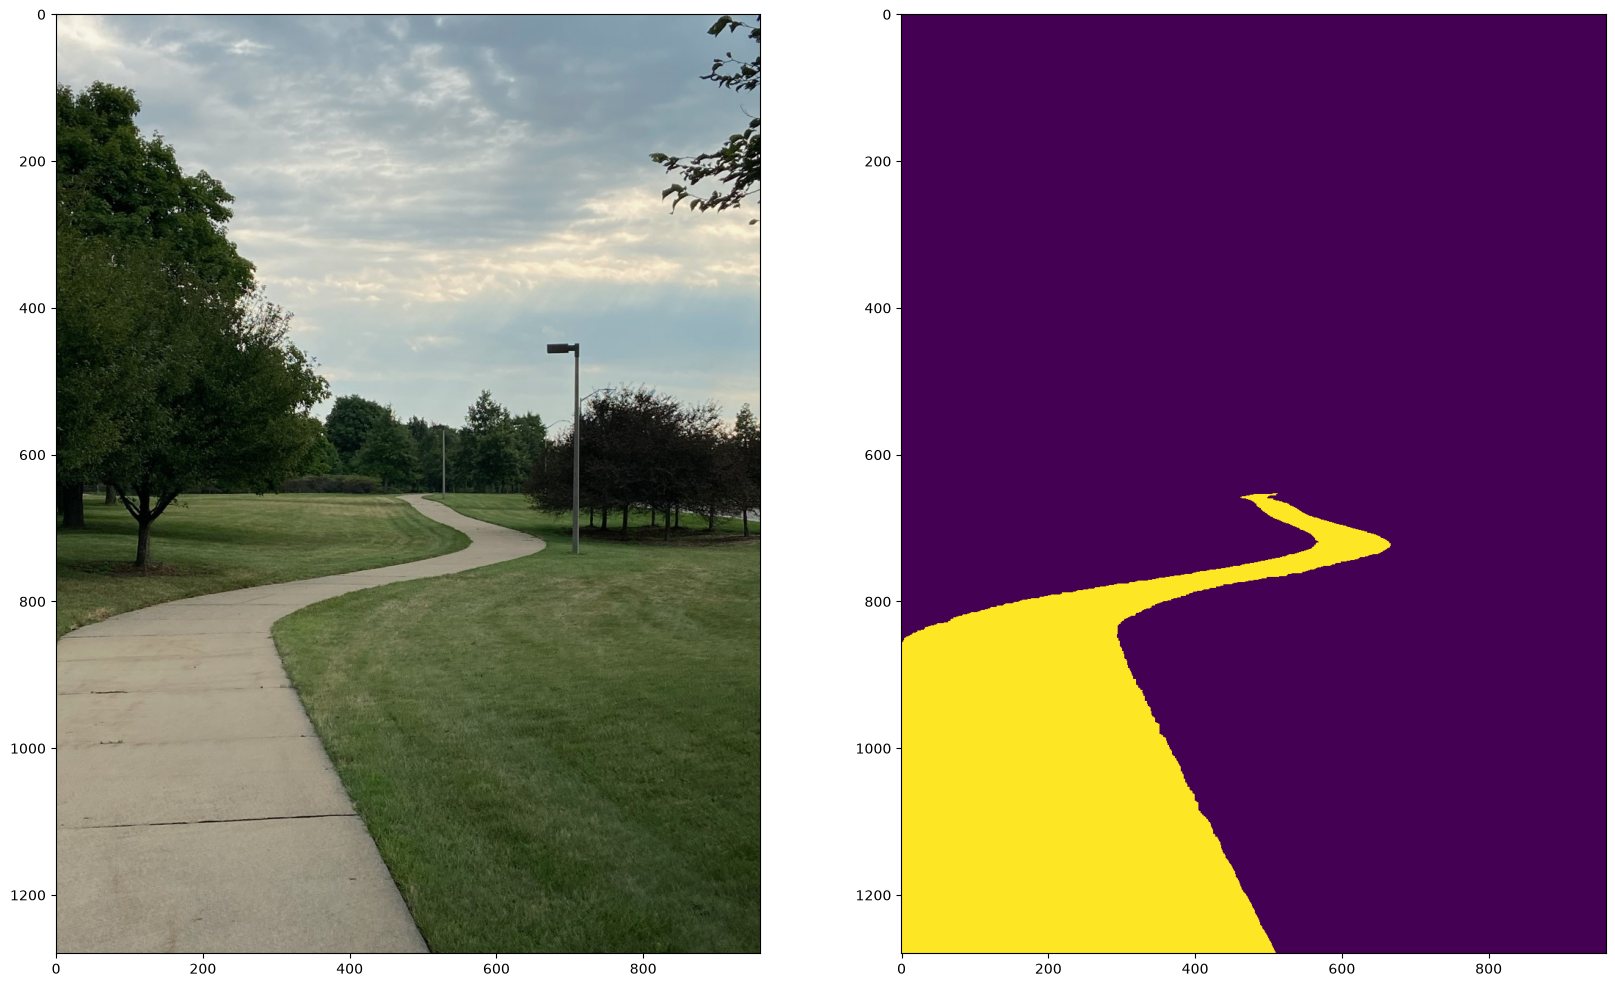

In [2]:
from imageio import v3 as imageio

# img = imageio.imread('./Image_data/Examples/Headphones.jpeg')
# gmask = imageio.imread('./Image_data/Examples/Headphones_GT.png')

# img = imageio.imread('Image_data/Examples/AA_Chameleon.jpg')
# gmask = imageio.imread('Image_data/Examples/AA_Chameleon_GT.png')

img = imageio.imread('Image_data/Examples/a_walk_in_the_park.jpg')
gmask = imageio.imread('Image_data/Examples/a_walk_in_the_park_GT.png')

fig = plt.figure(figsize=(20, 20))
my_ax = fig.add_subplot(1, 2, 1)
my_ax.imshow(img)
my_ax = fig.add_subplot(1, 2, 2)
my_ax.imshow(gmask)

# Reduce image resolution to 25% for efficiency
scale = 0.25

img = resize(
    img,
    (int(img.shape[0] * scale), int(img.shape[1] * scale)),
    preserve_range=True,
    anti_aliasing=True
)

gmask = resize(
    gmask,
    img.shape[:2],
    order=0,
    preserve_range=True,
    anti_aliasing=False
)

In [3]:
from see import base_classes

# put data in a pipeline
mydata = base_classes.pipedata()
mydata.append([img])
mydata.gtruth.append(gmask)

----
<a name="Genetic_Algorithm_Search"></a>

## Genetic Algorithm Search

First import image files, as well as the following packages:

In [4]:
from see.Segmentors import segmentor
from see.ColorSpace import colorspace
from see.Workflow import workflow
from see.Segment_Fitness import segment_fitness
from see import base_classes, GeneticSearch

#define an algorithm workflow
#workflow.addalgos([colorspace, segmentor, segment_fitness])
workflow.addalgos([segmentor, segment_fitness])

To run the genetic algorithm, we need to initialize an instance of an evolver. The original image and ground truth segmentation image are inputs to it, along with an integer value for population size. This value sets how many indivudals are in our population. For this example, we'll set this number to be equal to 10.

In [5]:
#TODO This needs to be fixed Using the new syntax.
my_evolver = GeneticSearch.Evolver(workflow, mydata, pop_size=15)
#my_evolver = GeneticSearch.Evolver(workflow, mydata, pop_size=3)

Now that the evolver has been initialized, we can run the genetic algorithm for a specified number of generations (or iterations). Here we will set this number equal to 5.

In [6]:
# warnings may appear when this runs
population = my_evolver.run(ngen=50)

Initializing a new random population
Generation 0/50 of population size 15
<class 'see.Workflow.workflow'> parameters: 
	algorithm = QuickShift
	alpha1 = 0.984375
	alpha2 = 0.875
	beta1 = 0.71875
	beta2 = 0.01171875
	gamma1 = 0.06640625
	gamma2 = 0.03125
	n_segments = 2
	max_num_iter = 2

Time: 0.506 s
p_fitness=0.9986771303645856

<class 'see.Workflow.workflow'> parameters: 
	algorithm = Felzenszwalb
	alpha1 = 0.89453125
	alpha2 = 0.5078125
	beta1 = 0.6171875
	beta2 = 0.1796875
	gamma1 = 0.4296875
	gamma2 = 0.69140625
	n_segments = 7
	max_num_iter = 10

Time: 0.071 s
p_fitness=0.9998764357121471

<class 'see.Workflow.workflow'> parameters: 
	algorithm = QuickShift
	alpha1 = 0.48046875
	alpha2 = 0.84765625
	beta1 = 0.19140625
	beta2 = 0.5546875
	gamma1 = 0.078125
	gamma2 = 0.48046875
	n_segments = 7
	max_num_iter = 16

Time: 0.214 s
p_fitness=0.9997377774418191

<class 'see.Workflow.workflow'> parameters: 
	algorithm = ColorThreshold
	alpha1 = 0.19921875
	alpha2 = 0.8203125
	beta1 = 0.

In [7]:
print(my_evolver.hof[0].fitness)

(np.float64(0.012369791666666666),)


----
<a name="Reading_the_Results"></a>

## Reading the Results

After the genetic algorithm is complete, we can retrieve the individuals that resulted in the lowest (best) fitness values by printing `my_evolver.hof`. These individuals are sorted according to fitness value, so to get the overal best individual, we can simply look at the first individual in the list. 

In [8]:
params = my_evolver.hof[0]
fitness = params.fitness.values[0]
print(f'Best Individual ({fitness}):\n', params)

Best Individual (0.012369791666666666):
 ['ColorThreshold', 0.2734375, 0.08984375, 0.25390625, 0.94921875, 0.41796875, 0.62890625, 1, 16]


We can see the mask this individual generates by evaluating it, then plotting the result:

<class 'see.Workflow.workflow'> parameters: 
	algorithm = ColorThreshold
	alpha1 = 0.2734375
	alpha2 = 0.08984375
	beta1 = 0.25390625
	beta2 = 0.94921875
	gamma1 = 0.41796875
	gamma2 = 0.62890625
	n_segments = 1
	max_num_iter = 16



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.5858478897835052..247.76876379596865].


Time: 0.006 s


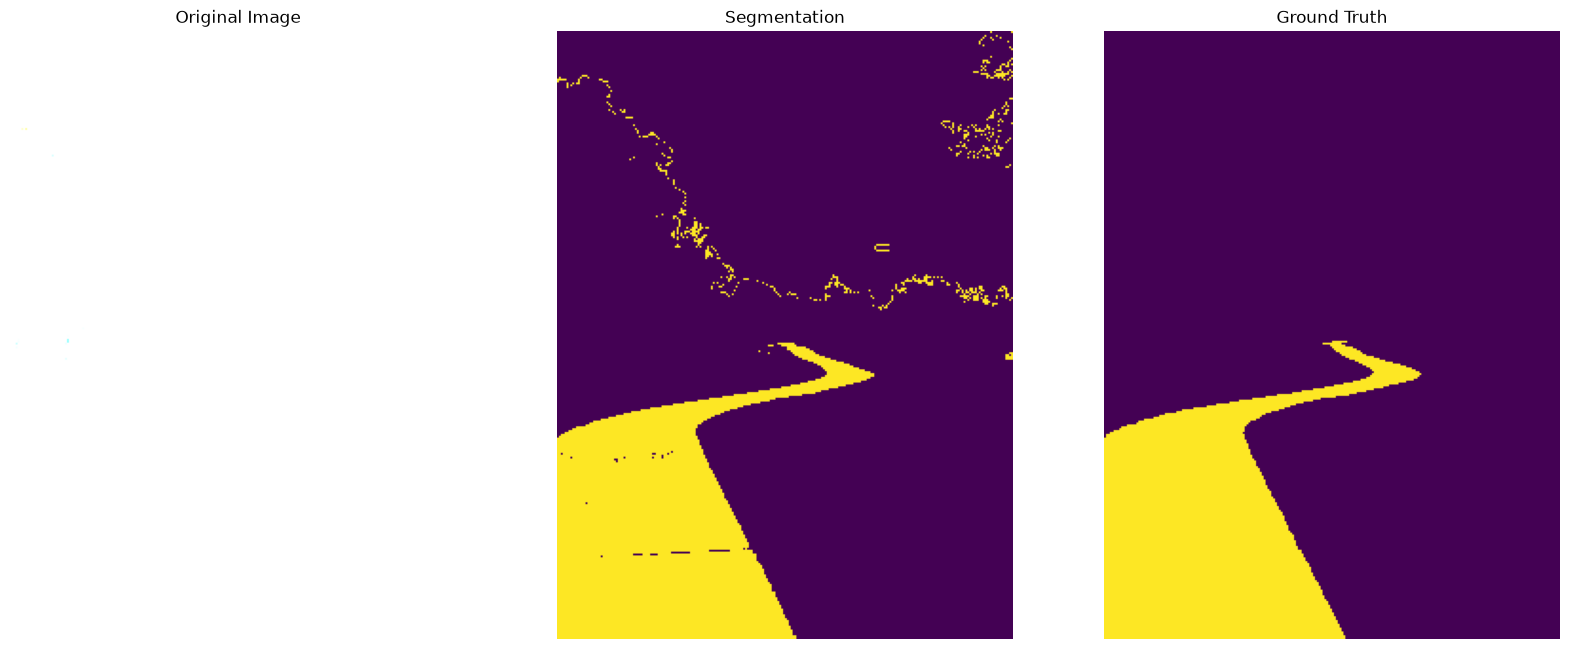

In [9]:
seg = workflow(params)
data = seg.runAlgo(mydata)

plt.figure(figsize=(20, 10))
plt.subplot(131)
plt.imshow(data[0][0])
plt.title("Original Image")
plt.axis('off')

plt.subplot(132)
plt.imshow(data[0][-1])
plt.title("Segmentation")
plt.axis('off')

plt.subplot(133)
plt.imshow(data.gtruth[0])
plt.title("Ground Truth")
plt.axis('off')


plt.tight_layout
plt.show()

We can also use `FitnessFunction` to calculate the final fitness value for this algorithm:

In [10]:
print('Fitness Value: ', data.fitness)

Fitness Value:  0.012369791666666666
